# Week 7 — Object recognition resit

**MVP:** count reusable drink bottles in at least 10 photos taken by me. A student-event organiser could use the count as a rough check before providing disposable cups.

This notebook follows the official Week 7 workshop order: own photos → ground truth → ready-made model → evaluation → failure and responsible use. The named Brightspace starter file was not available in the course content when checked on 30 October 2026.

## 0. Setup
Run this notebook in Google Colab. It uses a ready-made object-recognition model rather than training a new model.

In [1]:
!pip -q install transformers timm

from pathlib import Path
from PIL import Image, ImageDraw
from transformers import pipeline
import pandas as pd
import matplotlib.pyplot as plt

zsh:1: command not found: pip


/private/tmp/week7-resit-venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


/private/tmp/week7-resit-venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Add my own photos
The ten photos I took are stored in `technical/week7_photos` in this repository. They include five normal one-bottle photos, three zero-bottle controls and two difficult one-bottle cases using partial obstruction or low light. No recognisable people are included.

In [2]:
REPO_FOLDER = Path('ai4g-portfolio-MaxLopez')
if not REPO_FOLDER.exists():
    !git clone -q https://github.com/Maxlopez02/ai4g-portfolio-MaxLopez.git
PHOTO_FOLDER = REPO_FOLDER / 'Resit' / 'Week 7' / 'technical' / 'week7_photos'
image_paths = sorted([p for p in PHOTO_FOLDER.glob('*') if p.suffix.lower() in {'.jpg', '.jpeg', '.png'}])
print('Photos found:', len(image_paths))
for path in image_paths:
    print(path.name)
assert len(image_paths) >= 10, 'Upload at least 10 permitted photos before continuing.'

Photos found: 10
difficult_bottle_01.png
difficult_bottle_02.png
one_bottle_01.png
one_bottle_02.png
one_bottle_03.png
one_bottle_04.png
one_bottle_05.png
zero_bottles_01.png
zero_bottles_02.png
zero_bottles_03.png


## 2. Ground truth — fill this in before running the model
For every printed filename, count the visible reusable drink bottles myself. Do not look at the model output first. Replace the example names below with the exact filenames.

In [3]:
GROUND_TRUTH = {
    'difficult_bottle_01.png': 1,
    'difficult_bottle_02.png': 1,
    'one_bottle_01.png': 1,
    'one_bottle_02.png': 1,
    'one_bottle_03.png': 1,
    'one_bottle_04.png': 1,
    'one_bottle_05.png': 1,
    'zero_bottles_01.png': 0,
    'zero_bottles_02.png': 0,
    'zero_bottles_03.png': 0,
}

missing = [p.name for p in image_paths if p.name not in GROUND_TRUTH]
extra = [name for name in GROUND_TRUTH if name not in {p.name for p in image_paths}]
assert not missing, f'Add a ground-truth bottle count for: {missing}'
assert not extra, f'These ground-truth names do not match a photo: {extra}'
pd.DataFrame({'filename': list(GROUND_TRUTH), 'true_bottles': list(GROUND_TRUTH.values())})

,filename,true_bottles
0,difficult_bottle_01.png,1
1,difficult_bottle_02.png,1
2,one_bottle_01.png,1
3,one_bottle_02.png,1
4,one_bottle_03.png,1
5,one_bottle_04.png,1
6,one_bottle_05.png,1
7,zero_bottles_01.png,0
8,zero_bottles_02.png,0
9,zero_bottles_03.png,0


## 3. Load the ready-made model
The model was trained on COCO object categories, including `bottle`. The pipeline converts each image to model input and returns a label, confidence score and box. `THRESHOLD` controls how confident a bottle prediction must be.

In [4]:
detector = pipeline('object-detection', model='facebook/detr-resnet-50')
THRESHOLD = 0.70
print('Confidence threshold:', THRESHOLD)

/private/tmp/week7-resit-venv/lib/python3.9/site-packages/torch/nn/modules/module.py:2441: UserWarning: for conv1.weight: copying from a non-meta parameter in the checkpoint to a meta parameter in the current model, which is a no-op. (Did you mean to pass `assign=True` to assign items in the state dictionary to their corresponding key in the module instead of copying them in place?)
  warnings.warn(
/private/tmp/week7-resit-venv/lib/python3.9/site-packages/torch/nn/modules/module.py:2441: UserWarning: for bn1.weight: copying from a non-meta parameter in the checkpoint to a meta parameter in the current model, which is a no-op. (Did you mean to pass `assign=True` to assign items in the state dictionary to their corresponding key in the module instead of copying them in place?)
  warnings.warn(
/private/tmp/week7-resit-venv/lib/python3.9/site-packages/torch/nn/modules/module.py:2441: UserWarning: for bn1.bias: copying from a non-meta parameter in the checkpoint to a meta parameter in the

Some weights of the model checkpoint at facebook/detr-resnet-50 were not used when initializing DetrForObjectDetection: ['model.backbone.conv_encoder.model.layer1.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer2.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer3.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer4.0.downsample.1.num_batches_tracked']
- This IS expected if you are initializing DetrForObjectDetection from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing DetrForObjectDetection from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


Device set to use mps:0


Confidence threshold: 0.7


## 4. Run the MVP
A prediction counts only when the label is `bottle` and the confidence is at least the threshold.

In [5]:
results = []
predictions_by_file = {}

for path in image_paths:
    image = Image.open(path).convert('RGB')
    all_predictions = detector(image)
    bottles = [p for p in all_predictions if p['label'].lower() == 'bottle' and p['score'] >= THRESHOLD]
    predictions_by_file[path.name] = bottles
    true_count = GROUND_TRUTH[path.name]
    predicted_count = len(bottles)
    results.append({
        'filename': path.name,
        'true_bottles': true_count,
        'predicted_bottles': predicted_count,
        'absolute_count_error': abs(predicted_count - true_count),
    })

results_df = pd.DataFrame(results)
results_df

,filename,true_bottles,predicted_bottles,absolute_count_error
0,difficult_bottle_01.png,1,1,0
1,difficult_bottle_02.png,1,1,0
2,one_bottle_01.png,1,7,6
3,one_bottle_02.png,1,1,0
4,one_bottle_03.png,1,1,0
5,one_bottle_04.png,1,1,0
6,one_bottle_05.png,1,1,0
7,zero_bottles_01.png,0,0,0
8,zero_bottles_02.png,0,0,0
9,zero_bottles_03.png,0,0,0


## 5. Evaluate
The official workshop allows count error for object recognition. I use **mean absolute count error (MAE)** because the MVP question is “how many bottles?” A score of 0 means every photo had the correct count; lower is better. I also report exact-count accuracy because it is easy to explain.

In [6]:
mae = results_df['absolute_count_error'].mean()
exact_accuracy = (results_df['absolute_count_error'] == 0).mean()
print('Mean absolute count error:', round(mae, 2), 'bottles per photo')
print('Exact-count accuracy:', f'{exact_accuracy:.0%}')
print('Total true bottles:', int(results_df['true_bottles'].sum()))
print('Total predicted bottles:', int(results_df['predicted_bottles'].sum()))

Mean absolute count error: 0.6 bottles per photo
Exact-count accuracy: 90%
Total true bottles: 7
Total predicted bottles: 13


## 6. Show detections and find a failure
Red boxes are bottle predictions. Compare each image with the ground-truth count and choose one real failure to discuss.

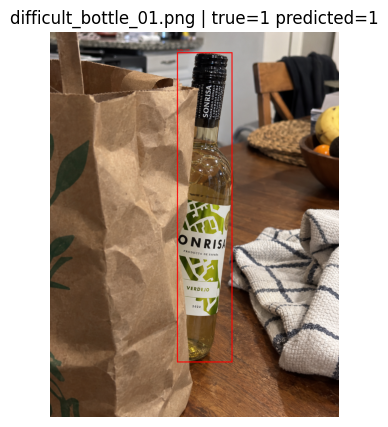

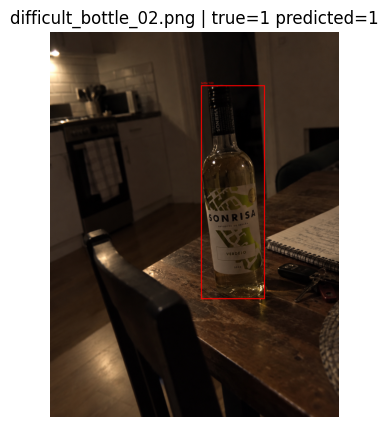

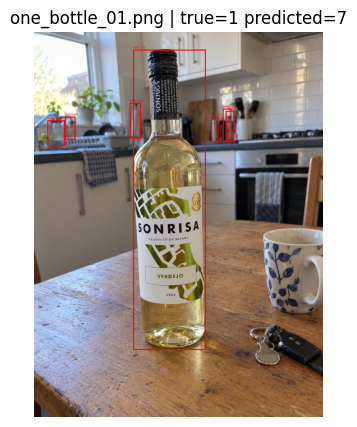

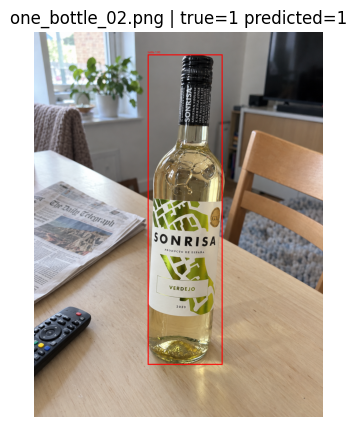

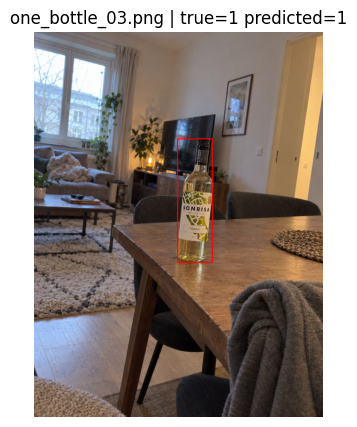

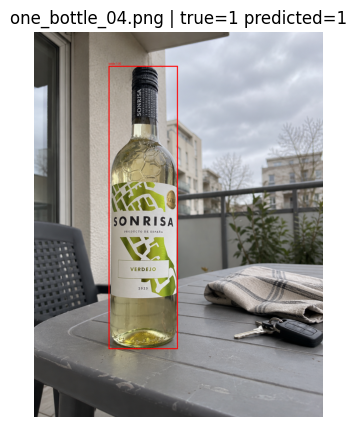

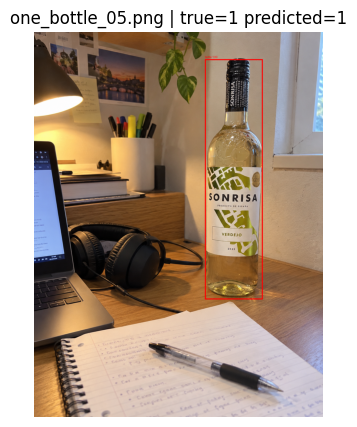

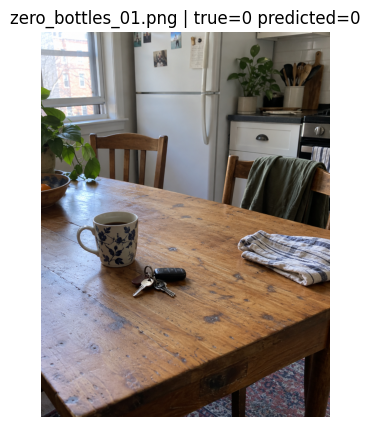

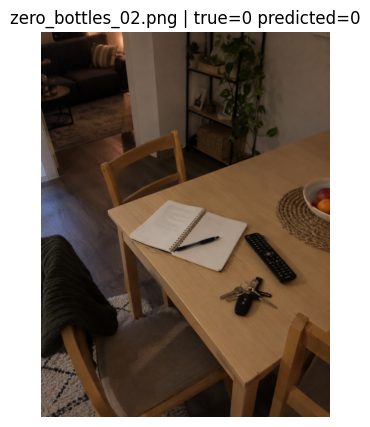

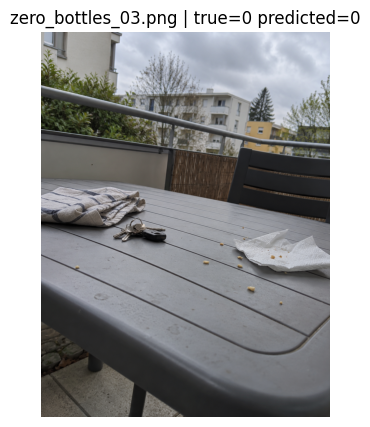

In [7]:
for path in image_paths:
    image = Image.open(path).convert('RGB')
    draw = ImageDraw.Draw(image)
    for prediction in predictions_by_file[path.name]:
        box = prediction['box']
        draw.rectangle((box['xmin'], box['ymin'], box['xmax'], box['ymax']), outline='red', width=4)
        draw.text((box['xmin'], max(0, box['ymin'] - 14)), f"bottle {prediction['score']:.2f}", fill='red')
    row = results_df.loc[results_df['filename'] == path.name].iloc[0]
    plt.figure(figsize=(7, 5))
    plt.imshow(image)
    plt.title(f"{path.name} | true={row['true_bottles']} predicted={row['predicted_bottles']}")
    plt.axis('off')
    plt.show()

## 7. My conclusion — complete after running

- **Result:** The mean absolute count error was 0.6 bottles per photo and exact-count accuracy was 90%. Nine of the ten photos had the correct count.
- **One real failure:** In `one_bottle_01.png`, the model predicted 7 bottles while the ground truth was 1.
- **Likely reason:** The kitchen background contains several narrow containers and dark vertical objects. The model correctly found the real bottle but also marked background objects as bottles, creating six false positives.
- **Who could be harmed:** If an organiser trusted a wrong count, they could under-supply drinking options. This is a small demo, but the same mistake in a safety or medical setting could be more serious.
- **Safeguard:** Treat the count as a suggestion, show the marked image and confidence, and let a person correct it. Test with different lighting and bottle types before wider use.

I would not deploy this MVP automatically from only ten photos. The small test is evidence of how the ready-made model behaves, not proof that it works for every event or user.